# Grupo 17:

Alicia Mei García Morín (100498828)

Ana Grima Vázquez de Prada (100495785)

El objetivo de esta práctica es identificar tipos de estrellas utilizando técnicas de aprendizaje no supervisado.

En este notebook se realiza el preprocesado de los datos, la reducción de dimensionalidad con PCA, la aplicación y comparación de distintos algoritmos de clustering, y la interpretación de los grupos obtenidos.

# 1. Carga de datos

En esta sección se cargan los datos que se utilizarán a lo largo de la práctica.



In [1]:
import pandas as pd
import numpy as np

SEED = 100498828
SEED_2 = 100498829
np.random.seed(SEED)

df = pd.read_csv("stars_data.csv")


# 2. EDA


## 2.1. Dimensiones del dataset


En esta sección se realiza un análisis exploratorio básico del dataset con el objetivo de entender su estructura y preparar el posterior preprocesamiento.

In [2]:
print("Dimensiones del dataset:", df.shape)
df.head()

Dimensiones del dataset: (240, 6)


,Temperature,L,R,A_M,Color,Spectral_Class
0,3068,0.002400,0.1700,16.12,Red,M
1,3042,0.000500,0.1542,16.60,Red,M
2,2600,0.000300,0.1020,18.70,Red,M
3,2800,0.000200,0.1600,16.65,Red,M
4,1939,0.000138,0.1030,20.06,Red,M


El dataset contiene:
- 240 instancias (filas) = número de estrellas
- 6 atributos (columnas) = número de atributos

In [3]:
df.dtypes


Temperature         int64
L                 float64
R                 float64
A_M               float64
Color              object
Spectral_Class     object
dtype: object

In [4]:
categorical_columns = df.select_dtypes(include=["object"]).columns
numerical_columns   = df.select_dtypes(include=["int64","float64"]).columns

print("Categóricas:", list(categorical_columns))
print("Numéricas:", list(numerical_columns))

Categóricas: ['Color', 'Spectral_Class']
Numéricas: ['Temperature', 'L', 'R', 'A_M']


Se identifican 2 variables categóricas (de tipo objeto): `Color` y `Spectral_Class`

Y 4 variables numéricas (aquellas de tipo entero o flotante): `Temperature`, `L`, `R` y `A_M`.

El problema planteado corresponde a un problema de aprendizaje automático no supervisado (no hay vble objetivo), concretamente de clustering. El objetivo es agrupar las estrellas en función de sus características físicas y espectrales, identificando posibles grupos naturales en los datos.

## 2.2. Cardinalidad de variables categóricas

In [5]:
categorical_columns = df.select_dtypes(include=["object"]).columns
cardinality = df[categorical_columns].nunique()
cardinality

Color             17
Spectral_Class     7
dtype: int64

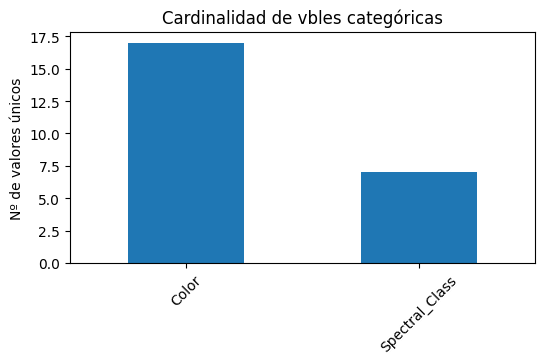

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,3))
cardinality.plot(kind="bar")
plt.title("Cardinalidad de vbles categóricas")
plt.ylabel("Nº de valores únicos")
plt.xticks(rotation=45)
plt.show()

Se observa que la variable `Color` presenta una mayor cardinalidad que `Spectral_Class`, ya que contiene un mayor número de valores distintos.

No obstante, esta cardinalidad puede considerarse moderada y manejable en el contexto del análisis.

Se normalizarán las categorías de la variable `Color` para unificar denominaciones equivalentes (por ejemplo, distintas formas de escribir un mismo color), y se hará una codificación ordinal tanto de `Color` como de `Spectral_Class`, teniendo en cuenta que ambas variables están relacionadas con la energía y temperatura de las estrellas.

## 2.3. Valores ausentes

In [7]:
print("How many missing values per attribute:")
print("======================================")
print(df.isnull().sum())

How many missing values per attribute:
Temperature       0
L                 0
R                 0
A_M               0
Color             0
Spectral_Class    0
dtype: int64


Observamos que ninguna variable presenta valores ausentes.

## 2.4 Columnas constantes o tipo ID

In [8]:
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
print("Columnas constantes:", constant_cols)

id_cols = [col for col in df.columns if df[col].nunique() == len(df)]
print("Columnas tipo ID:", id_cols)

Columnas constantes: []
Columnas tipo ID: []


No se observan columnas constantes o columnas de ID.

## 2.5. Análisis de las variables numéricas

In [9]:
df[numerical_columns].describe()

,Temperature,L,R,A_M
count,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396
std,9552.425037,179432.244940,517.155763,10.532512
min,1939.000000,0.000080,0.008400,-11.920000
25%,3344.250000,0.000865,0.102750,-6.232500
50%,5776.000000,0.070500,0.762500,8.313000
75%,15055.500000,198050.000000,42.750000,13.697500
max,40000.000000,849420.000000,1948.500000,20.060000


Los estadísticos descriptivos muestran de nuevo que no existen valores faltantes en las variables numéricas.

Se observa además que las variables presentan escalas y rangos muy diferentes entre sí, lo que hace necesario aplicar un proceso de escalado antes de utilizar PCA y los algoritmos de clustering.

# 3. Preprocesamiento


## 3.1. Codificación de variables categóricas

El dataset contiene dos variables categóricas: `Color` y `Spectral_Class`.

La variable `Spectral_Class` tiene un orden físico natural, ya que la clasificación espectral ordena las estrellas desde las más calientes hasta las más frías: O, B, A, F, G, K, M. Por ello lo codificamos de forma ordinal.

La variable `Color` también está relacionada con la energía y temperatura de la estrella. Sin embargo, en el dataset aparecen distintas formas de escribir colores equivalentes, por lo que primero se normalizan estas categorías antes de codificarlas.

In [10]:
df_processed = df.copy()

df_processed["Color"] = (
    df_processed["Color"]
    .str.strip()
    .str.lower()
    .str.replace("-", " ", regex=False)
)

color_mapping = {
    "blue white": "blue white",
    "bluewhite": "blue white",
    "white": "white",
    "whitish": "white",
    "yellowish white": "yellow white",
    "yellow white": "yellow white",
    "white yellow": "yellow white",
    "yellowish": "yellow",
    "pale yellow orange": "orange",
    "orange red": "red",
    "red": "red",
    "orange": "orange",
    "blue": "blue"
}

df_processed["Color"] = df_processed["Color"].replace(color_mapping)

spectral_order = {
    "O": 0,
    "B": 1,
    "A": 2,
    "F": 3,
    "G": 4,
    "K": 5,
    "M": 6
}

color_order = {
    "blue": 0,
    "blue white": 1,
    "white": 2,
    "yellow white": 3,
    "yellow": 4,
    "orange": 5,
    "red": 6
}

df_processed["Spectral_Class_encoded"] = df_processed["Spectral_Class"].map(spectral_order)
df_processed["Color_encoded"] = df_processed["Color"].map(color_order)

df_processed.head()

,Temperature,L,R,A_M,Color,Spectral_Class,Spectral_Class_encoded,Color_encoded
0,3068,0.002400,0.1700,16.12,red,M,6,6
1,3042,0.000500,0.1542,16.60,red,M,6,6
2,2600,0.000300,0.1020,18.70,red,M,6,6
3,2800,0.000200,0.1600,16.65,red,M,6,6
4,1939,0.000138,0.1030,20.06,red,M,6,6


# 3.2. Selección de variables

Una vez codificadas las variables categóricas, vamos a construir la matriz de entrada que se utilizará para el análisis no supervisado.

Esta matriz incluye tanto las variables numéricas originales como las variables categóricas codificadas ordinalmente.

In [11]:
X = df_processed[
    [
        "Temperature",
        "L",
        "R",
        "A_M",
        "Color_encoded",
        "Spectral_Class_encoded"
    ]
]

X.head()

,Temperature,L,R,A_M,Color_encoded,Spectral_Class_encoded
0,3068,0.002400,0.1700,16.12,6,6
1,3042,0.000500,0.1542,16.60,6,6
2,2600,0.000300,0.1020,18.70,6,6
3,2800,0.000200,0.1600,16.65,6,6
4,1939,0.000138,0.1030,20.06,6,6


## 3.3. Escalado de variables

Antes de aplicar PCA y los algoritmos de clustering, escalamos las variables mediante `StandardScaler`, ya que estos métodos son sensibles a las diferencias de escala entre variables.

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

## 3.4. Reducción de dimensionalidad mediante PCA

Para facilitar la visualización de los datos y la tarea de clustering, se aplica PCA con dos componentes principales, tal y como indica el enunciado.

A partir de este punto, los algoritmos de clustering se aplicarán directamente sobre estas dos componentes principales.

In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)

X_pca = pca.fit_transform(X_scaled)

X_pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

X_pca_df.head()

,PC1,PC2
0,2.062933,-0.155353
1,2.082440,-0.173248
2,2.183931,-0.244008
3,2.096245,-0.169631
4,2.268088,-0.281221


In [14]:
explained_variance = pca.explained_variance_ratio_

print("Varianza explicada PC1:", round(explained_variance[0], 3))
print("Varianza explicada PC2:", round(explained_variance[1], 3))
print("Varianza total:", round(explained_variance.sum(), 3))

Varianza explicada PC1: 0.558
Varianza explicada PC2: 0.296
Varianza total: 0.853


Las dos primeras componentes principales explican una proporción significativa de la varianza total del dataset, lo que justifica su uso para la visualización y el análisis mediante clustering.

A continuación, se representa gráficamente la proyección de las estrellas en las dos primeras componentes principales. Esta visualización permite observar posibles agrupaciones naturales antes de aplicar los algoritmos de clustering.

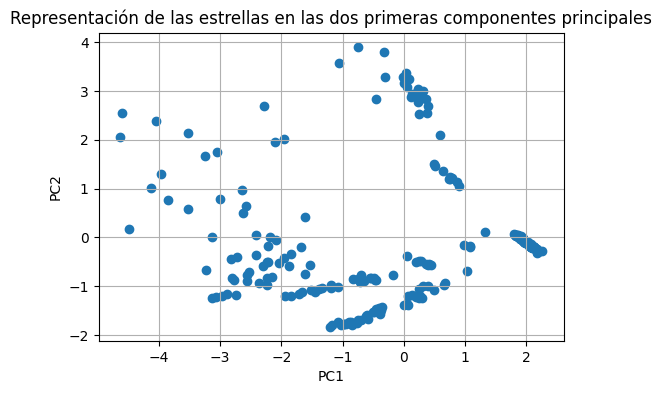

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.scatter(
    X_pca_df["PC1"],
    X_pca_df["PC2"]
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("Representación de las estrellas en las dos primeras componentes principales")

plt.grid(True)

plt.show()

Esto sugiere que los algoritmos de clustering pueden identificar grupos de estrellas con características similares. Por tanto, se procede a aplicar los métodos de clustering sobre estas dos componentes principales.

# 4. K-Means

## 4.1. Selección del número de clusters




Se aplica el algoritmo K-Means sobre las dos componentes principales obtenidas mediante PCA.

Para seleccionar el número adecuado de clusters se utilizan dos métricas:

- Inercia (Elbow method)
- Silhouette score

Estas métricas permiten evaluar la calidad de los agrupamientos obtenidos y seleccionar el número de clusters más adecuado.

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    labels = kmeans.fit_predict(X_pca_df)

    inertia.append(kmeans.inertia_)

    silhouette_scores.append(
        silhouette_score(X_pca_df, labels)
    )

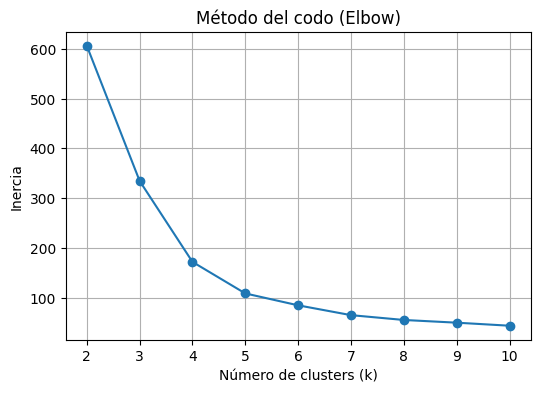

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.plot(
    K_range,
    inertia,
    marker="o"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")

plt.title("Método del codo (Elbow)")

plt.grid(True)

plt.show()

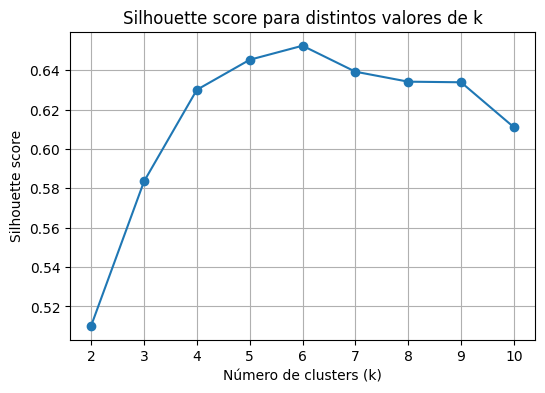

In [18]:
plt.figure(figsize=(6, 4))

plt.plot(
    K_range,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette score")

plt.title("Silhouette score para distintos valores de k")

plt.grid(True)

plt.show()

A partir del gráfico del método del codo (Elbow), se observa una reducción significativa de la inercia al aumentar el número de clusters desde k=2 hasta k=4 o k=5. A partir de ese punto, la disminución de la inercia se vuelve más gradual, lo que sugiere la presencia de un posible "codo" en torno a esos valores.

Por otro lado, el análisis del silhouette score muestra que el valor máximo se alcanza para k=6, lo que indica que esta configuración proporciona la mejor separación y cohesión entre los clusters en comparación con el resto de valores evaluados.

Teniendo en cuenta ambas métricas, se selecciona **k=6** como número de clusters para aplicar el algoritmo **K-Means**, ya que combina una buena reducción de la inercia con el mayor valor de silhouette score, lo que sugiere una estructura de agrupamiento adecuada en los datos.

## 4.2. Aplicación final de K-Means

In [19]:
kmeans = KMeans(
    n_clusters=6,
    random_state=SEED,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_pca_df)

X_pca_df["cluster_kmeans"] = kmeans_labels

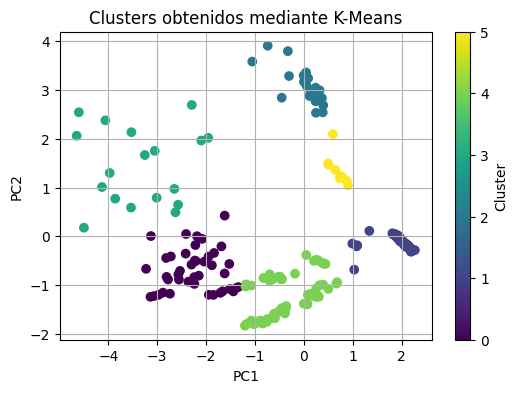

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.scatter(
    X_pca_df["PC1"],
    X_pca_df["PC2"],
    c=X_pca_df["cluster_kmeans"],
    cmap="viridis"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("Clusters obtenidos mediante K-Means")

plt.colorbar(label="Cluster")

plt.grid(True)

plt.show()

La representación gráfica de los datos en el espacio de las dos primeras componentes principales muestra que el algoritmo K-Means ha identificado **seis grupos diferenciados de estrellas**.

Se observa que los clusters están relativamente bien separados entre sí, lo que indica que el número de clusters seleccionado (k=6) permite capturar adecuadamente la estructura de los datos. Cada color representa un grupo de estrellas con características similares en términos de temperatura, luminosidad, radio y magnitud absoluta.

Estos resultados sugieren que el algoritmo K-Means es capaz de segmentar las estrellas en grupos coherentes, lo que facilita la posterior interpretación y caracterización de los distintos tipos de estrellas.

# 5. Hierarchical Clustering/Dendrogramas

En este apartado se aplica clustering jerárquico sobre los datos transformados mediante PCA (2 componentes).

El clustering jerárquico permite analizar la estructura de los datos mediante un dendrograma, que muestra cómo se van agrupando las observaciones.

Se evaluarán distintas funciones de *linkage* y se seleccionará la mejor configuración en función de métricas internas.

## 5.1. Construcción de dendrogramas

Se generan dendrogramas utilizando diferentes funciones de *linkage* para analizar cómo se forman los clusters:

- Ward
- Complete
- Average

Esto permite observar la estructura jerárquica de los datos y estimar el número adecuado de clusters.

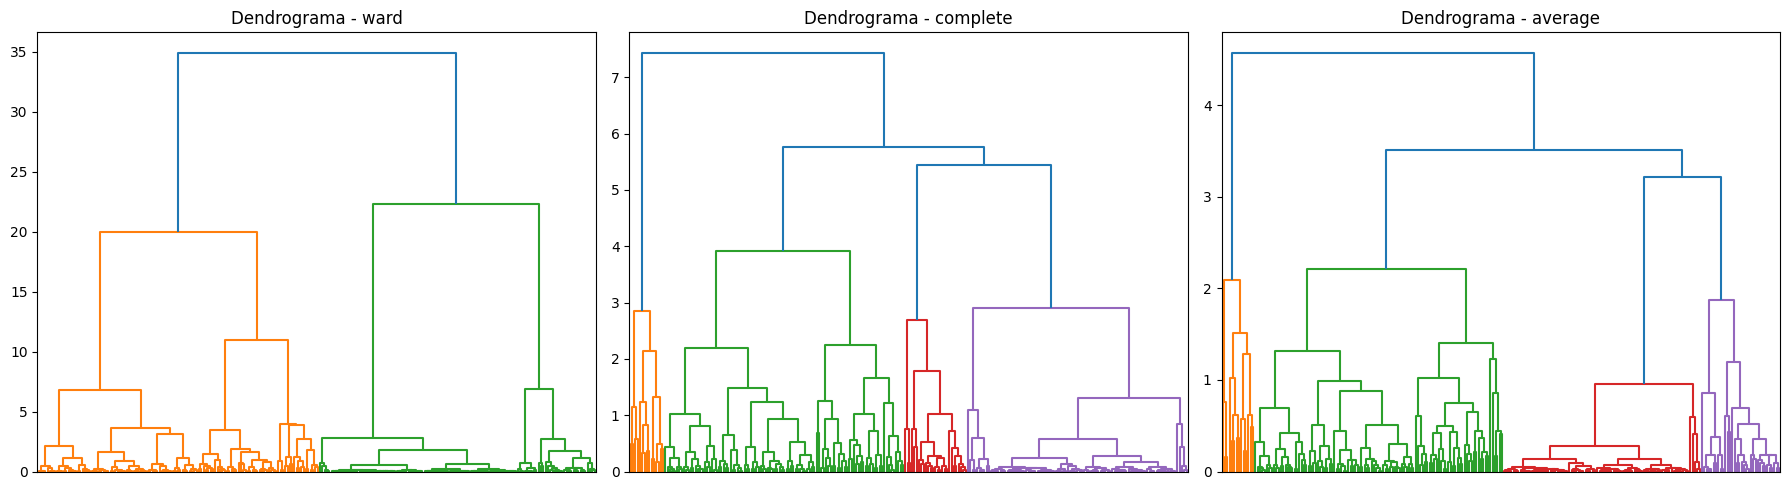

In [21]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

linkages = ['ward', 'complete', 'average']

plt.figure(figsize=(18, 5))

for i, method in enumerate(linkages):
    plt.subplot(1, 3, i+1)
    Z = linkage(X_pca, method=method)
    dendrogram(Z, no_labels=True)
    plt.title(f"Dendrograma - {method}")

plt.tight_layout()
plt.show()

## 5.2. Análisis de los dendrogramas

A partir de los dendrogramas se observa que:

- **Ward** genera clusters más compactos y equilibrados.
- **Complete** tiende a separar más los clusters.
- **Average** produce agrupaciones intermedias.

Además, los dendrogramas permiten estimar de forma visual el número de clusters, observando los saltos más significativos en la distancia de agrupación.

## 5.3. Evaluación de distintas configuraciones

Se prueban diferentes combinaciones de:
- Función de linkage
- Número de clusters (k)

Para cada combinación se calcula el **Silhouette Score**, que mide la calidad del clustering.

In [22]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for method in linkages:
    for k in range(2, 10):
        model = AgglomerativeClustering(n_clusters=k, linkage=method)
        labels = model.fit_predict(X_pca)
        score = silhouette_score(X_pca, labels)
        results.append((method, k, score))

df_results = pd.DataFrame(results, columns=['linkage', 'k', 'silhouette'])
df_results_sorted = df_results.sort_values(by='silhouette', ascending=False)
df_results_sorted.head(10)

,linkage,k,silhouette
14,complete,8,0.643883
21,average,7,0.638704
12,complete,6,0.635783
19,average,5,0.635547
22,average,8,0.634781
4,ward,6,0.634549
3,ward,5,0.632739
2,ward,4,0.632253
13,complete,7,0.624957
5,ward,7,0.622589


Se observa que la mejor configuración corresponde al método **complete** con **8 clusters**, al obtener el mayor valor de Silhouette Score.

Las siguientes configuraciones presentan valores similares, lo que indica que la estructura de los datos es relativamente estable frente a pequeñas variaciones en los parámetros.

## 5.4. Selección del mejor modelo

Aunque el análisis visual de los dendrogramas proporciona una primera aproximación, la selección final del modelo se realiza mediante evaluación cuantitativa.

En nuestro caso, el **Silhouette Score** muestra que la mejor configuración es el linkage **complete** con **8 clusters**, al obtener el valor más alto de esta métrica entre todas las combinaciones evaluadas.

Esto indica un buen equilibrio entre cohesión intra-cluster y separación inter-cluster.

Por tanto, se selecciona esta configuración como modelo final de clustering jerárquico.

In [23]:
best = df_results.sort_values(by='silhouette', ascending=False).iloc[0]

best_linkage = best['linkage']
best_k = int(best['k'])

hc = AgglomerativeClustering(n_clusters=best_k, linkage=best_linkage)
hc_labels = hc.fit_predict(X_pca)

print(f"Mejor linkage: {best_linkage}")
print(f"Mejor número de clusters: {best_k}")

Mejor linkage: complete
Mejor número de clusters: 8


## 5.5. Visualización de los clusters

Se representan los clusters obtenidos en el espacio de las dos componentes principales.

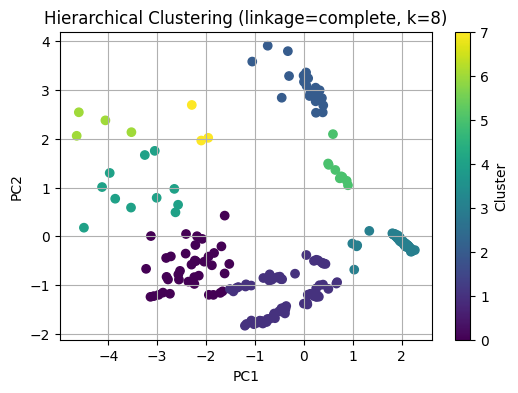

In [24]:
plt.figure(figsize=(6,4))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=hc_labels,
    cmap='viridis'
)

plt.title(f"Hierarchical Clustering (linkage={best_linkage}, k={best_k})")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Cluster")
plt.grid(True)

plt.show()

## 5.6. Conclusión del clustering jerárquico

El mejor modelo de clustering jerárquico obtenido utiliza **linkage complete** y **8 clusters**, al ser la configuración que alcanza el mayor valor de **Silhouette Score** entre todas las combinaciones evaluadas.

Este resultado indica que, en el espacio reducido mediante PCA, los datos presentan una estructura con varios grupos diferenciados. En comparación con K-Means, el clustering jerárquico permite además observar la relación entre los grupos mediante los dendrogramas, lo que aporta una interpretación adicional sobre la estructura de los datos.

El número de clusters obtenido (8) sugiere que los datos presentan una estructura relativamente compleja, lo cual puede estar relacionado con la diversidad de tipos de estrellas presentes en el dataset.

# 6. DBSCAN


DBSCAN es un algoritmo de clustering basado en densidad que permite detectar clusters de forma arbitraria y además identificar ruido (outliers).

A diferencia de K-Means o Hierarchical Clustering, no requiere especificar el número de clusters, sino dos hiperparámetros:
- **eps**: radio de vecindad
- **min_samples**: número mínimo de puntos para formar un cluster

Para evaluar DBSCAN se utilizará la métrica **DBCV**.

## 6.1. Estimación del parámetro eps

Para estimar un valor adecuado de **eps**, se utiliza el gráfico de distancias a los k vecinos más cercanos (k-distance plot).

El valor óptimo de eps se identifica como el punto donde la curva presenta un cambio brusco (codo).

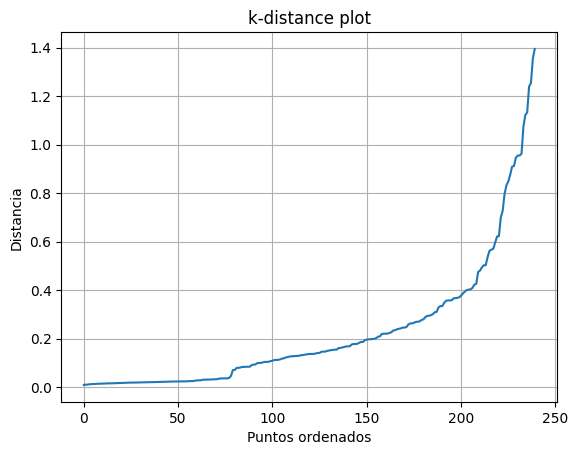

In [25]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_pca)
distances, indices = neighbors_fit.kneighbors(X_pca)

distances = np.sort(distances[:,4])

plt.plot(distances)
plt.title("k-distance plot")
plt.xlabel("Puntos ordenados")
plt.ylabel("Distancia")
plt.grid(True)
plt.show()

A partir del gráfico k-distance, se puede estimar un valor inicial de **eps** en torno a **0.5-0.7**, ya que en ese intervalo comienza a observarse un cambio brusco en la pendiente de la curva.

Por este motivo, en la búsqueda de hiperparámetros se prueban valores cercanos a ese intervalo.

## 6.2. Evaluación de distintas configuraciones

Se prueban diferentes combinaciones de:
- Valores de **eps**
- Valores de **min_samples**

Para cada combinación se evalúa la calidad del clustering.

Para DBSCAN, el enunciado indica que debe utilizarse la métrica **DBCV**, ya que es especialmente adecuada para algoritmos basados en densidad.

Sin embargo, dado que esta métrica no está disponible directamente en scikit-learn, se utiliza el **Silhouette Score** como métrica auxiliar para evaluar la calidad del clustering, permitiendo medir la cohesión intra-cluster y la separación inter-cluster de forma orientativa.

### IMPORTANTE

Instalación de la métrica DBCV

La métrica DBCV no está disponible directamente en scikit-learn, por lo que se instala una implementación externa. En este notebook se usa `%pip` porque el trabajo se está ejecutando en Visual Studio Code/Jupyter. En Colab Notebooks de Google Drive sería necesario sustituir `%pip` por `!pip`.

In [26]:
%pip install "git+https://github.com/FelSiq/DBCV"

  Cloning https://github.com/FelSiq/DBCV to C:\Users\Ana\AppData\Local\Temp\pip-req-build-bxq0_mb1
  Resolved https://github.com/FelSiq/DBCV to commit 13c3896ef78d12f1e3e1cbd394f2db9a09637ffd
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Note: you may need to restart the kernel to use updated packages.


  Running command git clone --filter=blob:none --quiet https://github.com/FelSiq/DBCV 'C:\Users\Ana\AppData\Local\Temp\pip-req-build-bxq0_mb1'


In [27]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import dbcv

eps_values = [0.2, 0.3, 0.5, 0.7]
min_samples_values = [3, 5, 10]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_pca)
        
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)
        
        if n_clusters > 1:
            silhouette = silhouette_score(X_pca, labels)
            dbcv_score = dbcv.dbcv(X_pca, labels)
            
            dbscan_results.append(
                (eps, min_samples, silhouette, dbcv_score, n_clusters, n_noise)
            )

## 6.3. Selección del mejor modelo

Se selecciona la configuración que obtiene el mayor valor de **DBCV**, ya que esta es la métrica indicada para evaluar DBSCAN.

El **Silhouette Score** se mantiene como métrica auxiliar para disponer de una referencia adicional sobre la separación entre clusters.

In [28]:
import pandas as pd

df_db = pd.DataFrame(
    dbscan_results,
    columns=['eps', 'min_samples', 'silhouette', 'dbcv', 'n_clusters', 'n_noise']
)

df_db_sorted = df_db.sort_values(by='dbcv', ascending=False)
df_db_sorted.head(10)

,eps,min_samples,silhouette,dbcv,n_clusters,n_noise
0,0.2,3,0.511654,0.771443,13,39
3,0.3,3,0.543033,0.713649,9,32
4,0.3,5,0.546132,0.703097,8,35
1,0.2,5,0.421041,0.693684,9,66
6,0.5,3,0.118919,0.649645,5,12
10,0.7,5,0.378684,0.610657,2,14
5,0.3,10,0.399826,0.587675,5,92
8,0.5,10,0.518076,0.572303,4,36
2,0.2,10,0.225133,0.435188,4,124
11,0.7,10,0.602981,0.351518,4,18


In [29]:
best_db = df_db_sorted.iloc[0]

best_eps = best_db['eps']
best_min_samples = int(best_db['min_samples'])

dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
db_labels = dbscan.fit_predict(X_pca)

print(f"Mejor eps: {best_eps}")
print(f"Mejor min_samples: {best_min_samples}")
print(f"Número de clusters: {int(best_db['n_clusters'])}")
print(f"Número de puntos de ruido: {int(best_db['n_noise'])}")
print(f"DBCV: {best_db['dbcv']:.4f}")
print(f"Silhouette Score: {best_db['silhouette']:.4f}")

Mejor eps: 0.2
Mejor min_samples: 3
Número de clusters: 13
Número de puntos de ruido: 39
DBCV: 0.7714
Silhouette Score: 0.5117


## 6.4. Visualización de los clusters

Se representan los clusters obtenidos, incluyendo los puntos considerados como ruido.

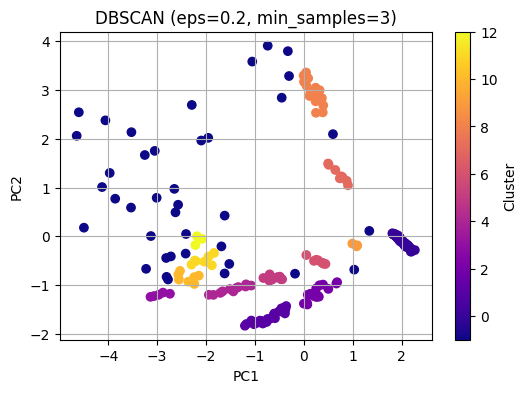

In [30]:
plt.figure(figsize=(6,4))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=db_labels,
    cmap='plasma'
)

plt.title(f"DBSCAN (eps={best_eps}, min_samples={best_min_samples})")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Cluster")
plt.grid(True)

plt.show()

Se observa que DBSCAN identifica varios clusters junto con puntos considerados como ruido (etiqueta -1).

Esto indica que existen observaciones que no pertenecen claramente a ningún grupo, lo cual puede ser relevante en el contexto de los datos de estrellas.

## 6.5. Conclusión del DBSCAN

El algoritmo DBSCAN permite identificar clusters de forma flexible, así como detectar puntos considerados como ruido, lo que supone una ventaja frente a métodos como K-Means.

La configuración óptima depende de los parámetros **eps** y **min_samples**, los cuales se han seleccionado mediante evaluación cuantitativa.

Sin embargo, DBSCAN es sensible a la elección de estos parámetros, lo que puede dificultar la obtención de una partición clara. En este caso, aunque se identifican agrupaciones en los datos, la estructura obtenida resulta menos clara que la obtenida con clustering jerárquico.

# 7. Análisis final

## 7.1. Reducción de dimensionalidad (PCA)

Se ha aplicado PCA para reducir la dimensionalidad de los datos a dos componentes principales, facilitando la visualización y el posterior análisis mediante técnicas de clustering.

Esta transformación permite representar las estrellas en un espacio bidimensional manteniendo la mayor parte de la variabilidad de los datos.


## 7.2. Clustering tras PCA

Sobre los datos transformados mediante PCA se han aplicado distintos algoritmos de clustering:

- K-Means
- Clustering jerárquico
- DBSCAN

Cada uno de ellos permite identificar agrupaciones en los datos desde diferentes perspectivas.


## 7.3. Comparación de resultados 

Se comparan los resultados obtenidos con los distintos algoritmos:

- **K-Means** genera clusters compactos, pero requiere fijar el número de clusters.
- **Clustering jerárquico** permite analizar la estructura de los datos y ha ofrecido los mejores resultados según el **Silhouette Score**, además de proporcionar una estructura interpretable mediante dendrogramas.
- **DBSCAN** permite detectar ruido y encontrar clusters de forma arbitraria, pero es más sensible a la elección de parámetros. En este caso, se ha evaluado mediante la métrica **DBCV**, específica para algoritmos basados en densidad, mostrando resultados menos claros en comparación con otros métodos.

En general, el clustering jerárquico proporciona la mejor combinación entre calidad del clustering e interpretabilidad en este dataset.

## 7.4. Pipeline recomendado

A partir de los resultados obtenidos, se propone el siguiente pipeline de clustering:

1. Aplicar **PCA con 2 componentes principales** para reducir la dimensionalidad de los datos y facilitar su visualización y análisis.
2. Utilizar **clustering jerárquico (Agglomerative Clustering)** con:
   - Linkage: **complete**
   - Número de clusters: **k = 8**

Esta configuración ha sido seleccionada al obtener el mejor resultado según el **Silhouette Score**, lo que indica un buen equilibrio entre cohesión intra-cluster y separación inter-cluster.

Además, el clustering jerárquico permite analizar la estructura de los datos mediante dendrogramas, lo que aporta una mayor interpretabilidad en comparación con otros métodos.

Por tanto, este pipeline proporciona una solución adecuada para agrupar las estrellas en función de sus características físicas.

# 8. Caracterización de los clusters obtenidos

Una vez seleccionado el pipeline recomendado, se caracterizan los clusters obtenidos mediante clustering jerárquico con **linkage complete** y **k=8**.

Para ello se analizan las variables originales mediante boxplots. Esto permite interpretar qué tipo de estrellas aparecen en cada grupo en función de su temperatura, luminosidad, radio, magnitud absoluta, color y clase espectral.

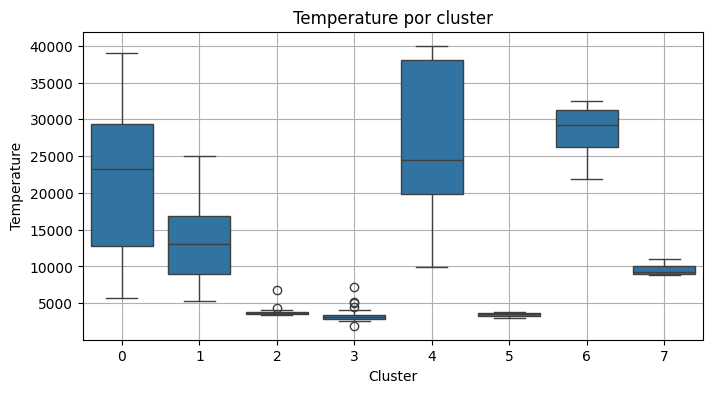

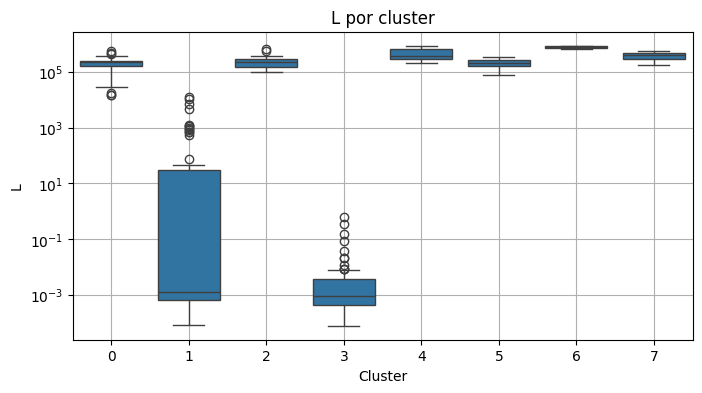

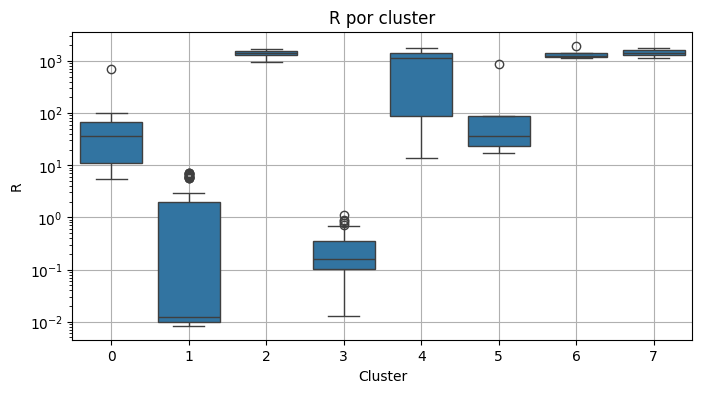

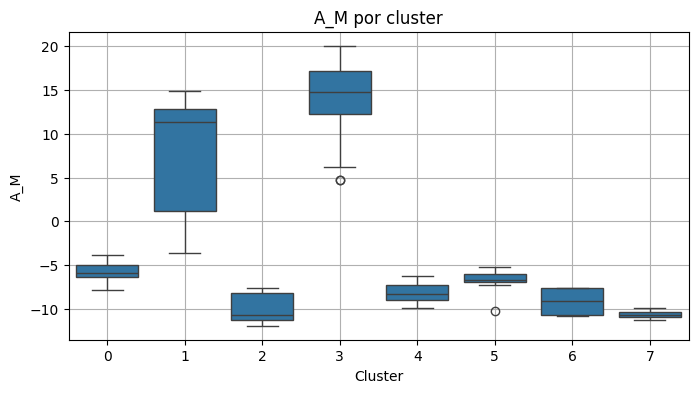

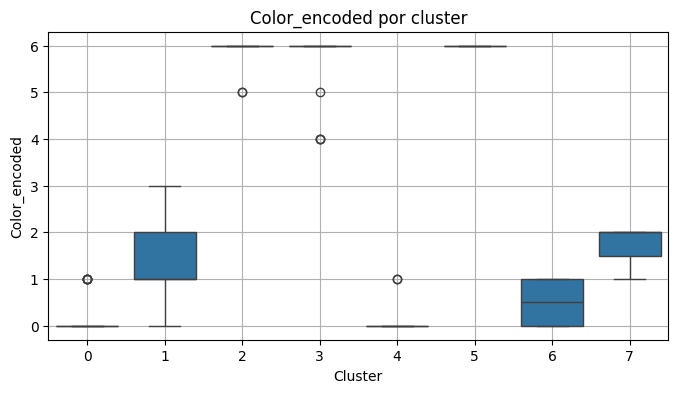

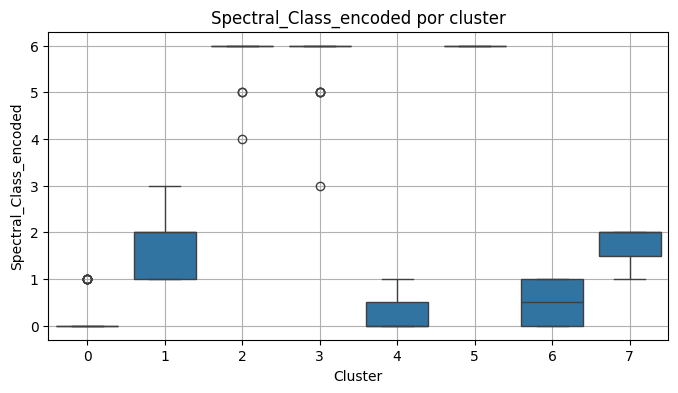

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clusters = df_processed.copy()
df_clusters["cluster_recomendado"] = hc_labels

variables_boxplot = [
    "Temperature",
    "L",
    "R",
    "A_M",
    "Color_encoded",
    "Spectral_Class_encoded"
]

for col in variables_boxplot:
    plt.figure(figsize=(8, 4))
    sns.boxplot(
        data=df_clusters,
        x="cluster_recomendado",
        y=col
    )
    plt.title(f"{col} por cluster")
    plt.xlabel("Cluster")
    plt.ylabel(col)
    
    if col in ["L", "R"]:
        plt.yscale("log")
        
    plt.grid(True)
    plt.show()

Además de los boxplots, se calcula un resumen estadístico de cada cluster para facilitar la interpretación de los grupos obtenidos.

In [32]:
resumen_clusters = df_clusters.groupby("cluster_recomendado").agg(
    n=("Temperature", "size"),
    Temperature_mediana=("Temperature", "median"),
    L_mediana=("L", "median"),
    R_mediana=("R", "median"),
    A_M_mediana=("A_M", "median"),
    Color_moda=("Color", lambda x: x.mode().iloc[0]),
    Spectral_Class_moda=("Spectral_Class", lambda x: x.mode().iloc[0])
)

resumen_clusters

,n,Temperature_mediana,L_mediana,R_mediana,A_M_mediana,Color_moda,Spectral_Class_moda
cluster_recomendado,,,,,,,
0,38,23267.5,221500.000000,36.0000,-5.9475,blue,O
1,65,12984.0,0.001340,0.0124,11.3400,blue white,B
2,24,3612.0,219000.000000,1384.5000,-10.7000,red,M
3,85,3192.0,0.000957,0.1600,14.7760,red,M
4,11,24490.0,374830.000000,1134.5000,-8.2400,blue,O
5,10,3574.5,197500.000000,37.0000,-6.6700,red,M
6,4,29289.0,791266.000000,1223.0000,-9.1500,blue,B
7,3,9235.0,404940.000000,1423.0000,-10.7300,white,A


## 8.1. Comparación con las clases astronómicas

Al comparar los clusters obtenidos con las clases astronómicas de referencia, se observan varias correspondencias relevantes.

Los clusters con temperaturas bajas, colores rojizos y clases espectrales tipo M se corresponden con estrellas frías, como las **enanas rojas o enanas marrones**, caracterizadas por baja luminosidad y pequeño radio.

Por otro lado, los clusters que presentan valores muy altos de luminosidad (L) y radio (R), junto con magnitudes absolutas muy negativas, se asemejan a **supergigantes o hipergigantes**, que son estrellas extremadamente brillantes y de gran tamaño.

Asimismo, los grupos con temperaturas elevadas, colores blancos o azulados y radios más pequeños pueden asociarse a **estrellas de secuencia principal** o incluso **enanas blancas**, dependiendo de sus valores de luminosidad y magnitud absoluta.

Aunque la correspondencia no es exacta, los clusters obtenidos reflejan patrones físicos coherentes con las categorías astronómicas reales, ya que variables como temperatura, luminosidad, radio y clase espectral permiten distinguir claramente distintos tipos de estrellas.

De forma más concreta, a partir del análisis de los boxplots y del resumen estadístico, se identifican clusters con baja luminosidad, radios pequeños y magnitudes absolutas positivas, asociados a estrellas compactas (enanas). Por otro lado, también aparecen clusters con luminosidades y radios muy elevados junto con magnitudes absolutas negativas, que se corresponden con estrellas de gran tamaño como supergigantes o hipergigantes.

# 9. Conclusiones finales

A partir de todo el análisis realizado, se concluye que:

- Los datos presentan una estructura con varios grupos diferenciados.
- El clustering jerárquico ha sido el método más adecuado, proporcionando resultados consistentes y fácilmente interpretables.
- DBSCAN permite detectar ruido, pero es más sensible a los parámetros y no ofrece una partición tan clara en este caso.
- La reducción mediante PCA facilita la visualización y el análisis, manteniendo la estructura de los datos.

En conjunto, el pipeline basado en PCA seguido de clustering jerárquico permite identificar patrones coherentes con las características físicas de las estrellas, lo que confirma la validez del enfoque aplicado.